# Powering the Planet

## Can economies grow while emitting less CO₂?

This report compares France, Germany, and Italy using Our World in Data. We first describe how each country's energy mix changed, then examine CO₂ emissions and ask whether GDP grew while emissions fell. The results describe what happened in the selected data; they do not establish what caused the changes.

The questions are:

1. How did the shares of coal, oil, gas, nuclear energy, and renewables change from 2000 to 2025?
2. How did total and per-person CO₂ emissions change from 2000 to 2024?
3. Did GDP rise while total CO₂ emissions fell from 2000 to 2022, and in which individual years did that happen?

## 1. Energy shares (2000–2025)

We compare five parts of each country's energy mix: coal, oil, gas, nuclear energy, and renewables. Each value is a share of total energy, expressed as a percentage. The fossil-fuel share is a separate summary of coal, oil, and gas, so it must not be added to the five parts. Subtracting a source's 2000 share from its 2025 share gives a change in **percentage points**. The endpoint chart shows how the five parts fit together; the table gives the exact changes.

In [1]:
from powering_the_planet.data import load_energy

energy = load_energy()
print(energy.shape)

(19494, 130)


In [2]:
sources = [
    "coal_energy_share_pct",
    "oil_energy_share_pct",
    "gas_energy_share_pct",
    "nuclear_energy_share_pct",
    "renewables_energy_share_pct",
]

energy.loc[
    energy["country"].isin(["France", "Germany", "Italy"])
    & energy["year"].isin([2000, 2025]),
    ["country", "year"] + sources,
].sort_values(["country", "year"])

,country,year,coal_energy_share_pct,oil_energy_share_pct,gas_energy_share_pct,nuclear_energy_share_pct,renewables_energy_share_pct
6407,France,2000,5.579835,37.267696,13.560395,41.012928,2.579149
6432,France,2025,1.754674,30.659094,12.205332,47.148453,8.232449
6880,Germany,2000,25.097248,39.727608,20.977600,13.001689,1.195857
6905,Germany,2025,14.882021,41.808468,28.144200,0.000000,15.165306
8979,Italy,2000,7.226488,54.311035,33.694370,0.000000,4.768109
9004,Italy,2025,1.555980,43.849777,39.119880,0.000000,15.474362


In [3]:
from powering_the_planet.analysis import select_energy_mix

energy_mix = select_energy_mix(energy)
print(energy_mix.shape)
energy_mix.groupby("country")["year"].agg(["min", "max", "count"])

(78, 8)


,min,max,count
country,,,
France,2000,2025,26
Germany,2000,2025,26
Italy,2000,2025,26


In [4]:
from powering_the_planet.analysis import energy_share_changes

energy_changes = energy_share_changes(energy_mix)
energy_changes.round(2)

,coal_energy_share_pct,oil_energy_share_pct,gas_energy_share_pct,nuclear_energy_share_pct,fossil_fuels_energy_share_pct,renewables_energy_share_pct
country,,,,,,
France,-3.83,-6.61,-1.36,6.14,-11.79,5.65
Germany,-10.22,2.08,7.17,-13.00,-0.97,13.97
Italy,-5.67,-10.46,5.43,0.00,-10.71,10.71


<Axes: title={'center': 'Energy sources in France, Germany, and Italy: 2000 vs 2025'}, ylabel='Share of total energy (%)'>

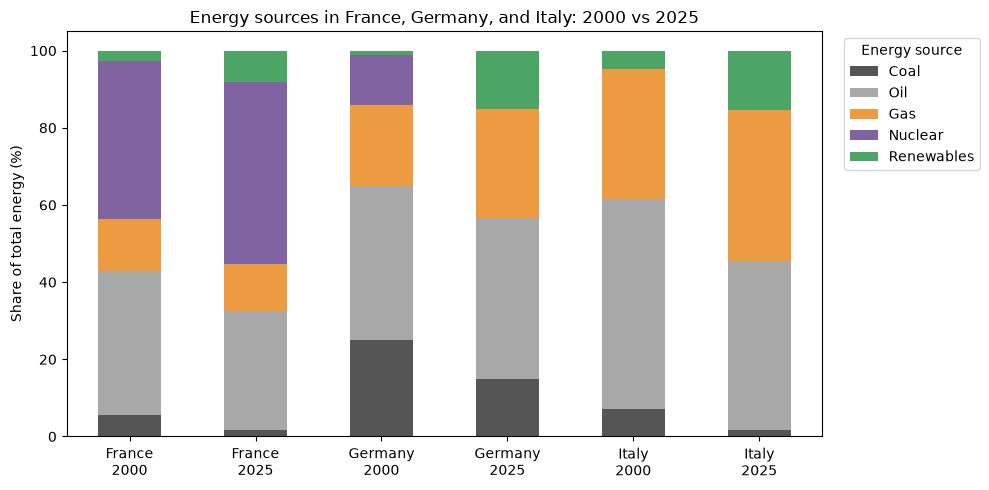

In [5]:
from powering_the_planet.plots import plot_energy_mix_endpoints

plot_energy_mix_endpoints(energy_mix)

France's coal, oil, and gas shares all fell, while nuclear energy and renewables gained share. Germany had the largest increase in renewable share (+13.97 percentage points), but its combined fossil-fuel share fell by only 0.97 points: coal declined while oil and gas rose, and nuclear energy fell to zero. In Italy, coal and oil lost share while gas and renewables gained; nuclear energy remained at zero. The chart and table describe the composition of energy use, not the total amount consumed. They do not establish why emissions changed.

## 2. CO₂ emissions (2000–2024)

We compare annual CO₂ emissions and emissions per person for France, Germany, and Italy. For each measure, percentage change is calculated as (2024 value − 2000 value) ÷ 2000 value × 100.

In [6]:
from powering_the_planet.data import load_co2

co2 = load_co2()
print(co2.shape)

(56269, 79)


In [7]:
from powering_the_planet.analysis import select_co2

co2_focus = select_co2(co2)
print(co2_focus.shape)
co2_focus.groupby("country")["year"].agg(["min", "max", "count"])

(75, 4)


,min,max,count
country,,,
France,2000,2024,25
Germany,2000,2024,25
Italy,2000,2024,25


In [8]:
from powering_the_planet.analysis import co2_percent_changes

co2_changes = co2_percent_changes(co2_focus)
co2_changes.round(2)

,co2,co2_per_capita
country,,
France,-35.98,-42.77
Germany,-36.16,-38.24
Italy,-36.44,-38.66


From 2000 to 2024, annual CO₂ emissions fell by 35.98% in France, 36.16% in Germany, and 36.44% in Italy. Emissions per person also fell by 42.77%, 38.24%, and 38.66%, respectively. Italy had the largest percentage decline in total emissions, while France had the largest decline per person. These numbers compare the two endpoint years.


## 3. GDP and CO₂ (2000–2022)

We use the GDP and CO₂ columns in the OWID CO₂ data. First, we compare 2022 with 2000 for each country. Then we compare each year with the preceding year to find when GDP rose while CO₂ emissions fell. We stop at 2022 because GDP values for France, Germany, and Italy are missing in 2023 and 2024. GDP is measured in international dollars at 2011 prices, adjusted for inflation and differences in living costs.

In [9]:
from powering_the_planet.analysis import select_gdp_co2

gdp_co2 = select_gdp_co2(co2)
print(gdp_co2.shape)
gdp_co2.groupby("country")["year"].agg(["min", "max", "count"])

(69, 4)


,min,max,count
country,,,
France,2000,2022,23
Germany,2000,2022,23
Italy,2000,2022,23


In [10]:
gdp_co2[["gdp", "co2"]].isna().sum()

gdp    0
co2    0
dtype: int64

In [11]:
from powering_the_planet.analysis import gdp_co2_percent_changes

changes = gdp_co2_percent_changes(gdp_co2)
changes

,gdp,co2
country,,
France,31.495806,-27.770014
Germany,43.811875,-25.468780
Italy,14.608050,-28.279919


From 2000 to 2022, GDP increased in France (31.5%), Germany (43.8%), and Italy (14.6%), while annual CO₂ emissions decreased by 27.8%, 25.5%, and 28.3%, respectively. These figures compare the two endpoint years; they do not show what happened in each year between them.

### CO₂ intensity of GDP

CO₂ intensity means annual CO₂ emissions divided by annual GDP. We set each country's value in 2000 to 100, then compare later years with that starting point. An index below 100 means the country emitted less CO₂ per unit of economic output than in 2000. The index shows the size of the change, not its cause.

In [12]:
from powering_the_planet.analysis import co2_intensity_index

intensity = co2_intensity_index(gdp_co2)
intensity[intensity["year"].isin([2000, 2022])].round(2)

,country,year,intensity_index
18435,France,2000,100.00
18457,France,2022,54.93
19652,Germany,2000,100.00
19674,Germany,2022,51.83
25494,Italy,2000,100.00
25516,Italy,2022,62.58


<Axes: title={'center': 'CO₂ per unit of GDP, 2000–2022'}, xlabel='Year', ylabel='Index (2000 = 100)'>

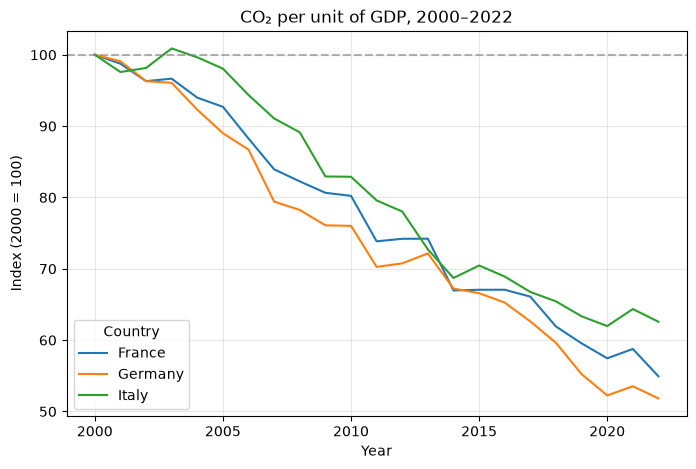

In [13]:
from powering_the_planet.plots import plot_co2_intensity

plot_co2_intensity(intensity)

By 2022, the CO₂ intensity index was 54.93 in France, 51.83 in Germany, and 62.58 in Italy. Compared with 2000, that is about 45%, 48%, and 37% less CO₂ per unit of GDP, respectively. The chart shows an overall decline with some year-to-year reversals; it does not tell us what caused the decline.

In [14]:
from powering_the_planet.analysis import years_gdp_up_co2_down

matching_years = years_gdp_up_co2_down(gdp_co2)
print(matching_years.shape)
matching_years

(26, 4)


,country,year,gdp_change_pct,co2_change_pct
18437,France,2002,1.421217,-1.091017
18441,France,2006,2.600851,-2.325935
18442,France,2007,2.509949,-2.504339
18443,France,2008,0.330397,-1.682440
18446,France,2011,2.173390,-5.947499
18449,France,2014,0.956178,-8.915131
18453,France,2018,1.865066,-4.584607
18454,France,2019,1.842976,-2.041909
18457,France,2022,2.562398,-4.132232
19654,Germany,2002,1.040631,-1.794082


The year-by-year comparison found 26 country-year cases where GDP increased while CO₂ emissions decreased from the preceding year: 9 in France, 10 in Germany, and 7 in Italy. All three countries met this condition in 2007, 2011, 2018, and 2019. This comparison shows what changed in those years; it does not explain why emissions fell.

## 4. Trends over time

The comparisons above show the change between the first and last years. The charts below show what happened between those years. In the GDP–CO₂ charts, both measures are set to 100 in 2000, making their relative changes comparable despite their different units.

<Axes: title={'center': 'Fossil-fuel share of total energy, 2000–2025'}, xlabel='Year', ylabel='Share of total energy (%)'>

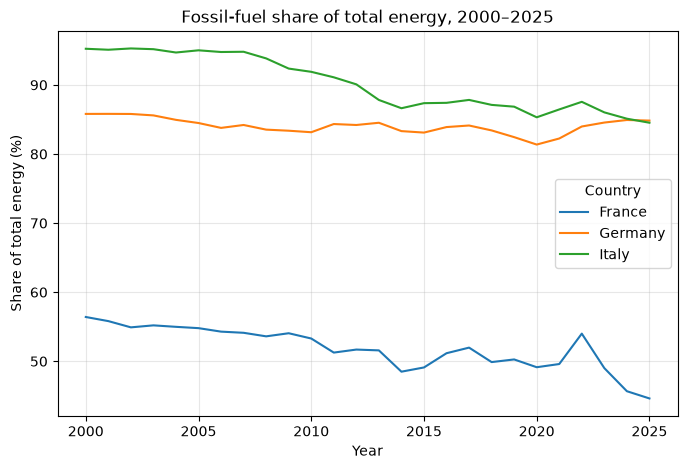

In [15]:
from powering_the_planet.plots import plot_energy_share

plot_energy_share(
    energy_mix,
    "fossil_fuels_energy_share_pct",
    "Fossil-fuel share of total energy, 2000–2025",
)

<Axes: title={'center': 'Renewable-energy share of total energy, 2000–2025'}, xlabel='Year', ylabel='Share of total energy (%)'>

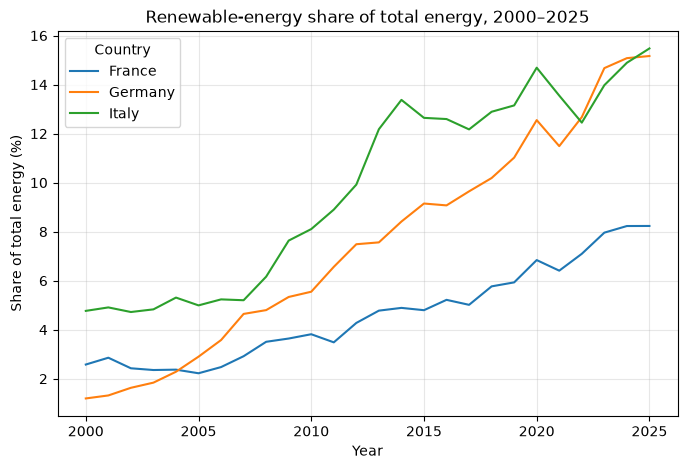

In [16]:
plot_energy_share(
    energy_mix,
    "renewables_energy_share_pct",
    "Renewable-energy share of total energy, 2000–2025",
)

<Axes: title={'center': 'Annual CO₂ emissions, 2000–2024'}, xlabel='Year', ylabel='Million tonnes of CO₂'>

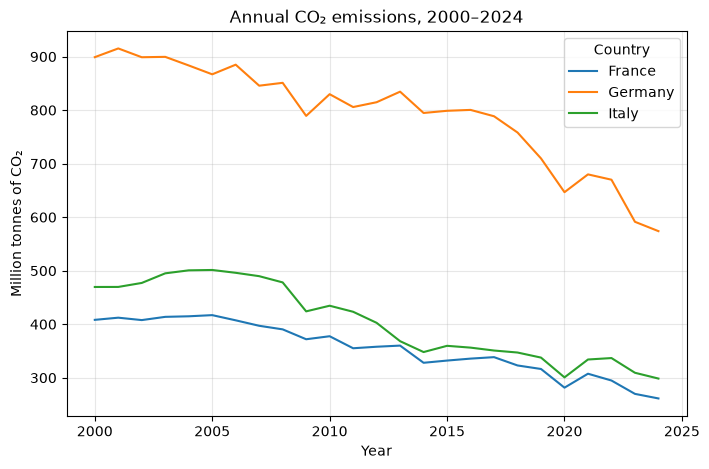

In [17]:
from powering_the_planet.plots import plot_co2

plot_co2(
    co2_focus,
    "co2",
    "Annual CO₂ emissions, 2000–2024",
    "Million tonnes of CO₂",
)

<Axes: title={'center': 'Annual CO₂ emissions per person, 2000–2024'}, xlabel='Year', ylabel='Tonnes of CO₂ per person'>

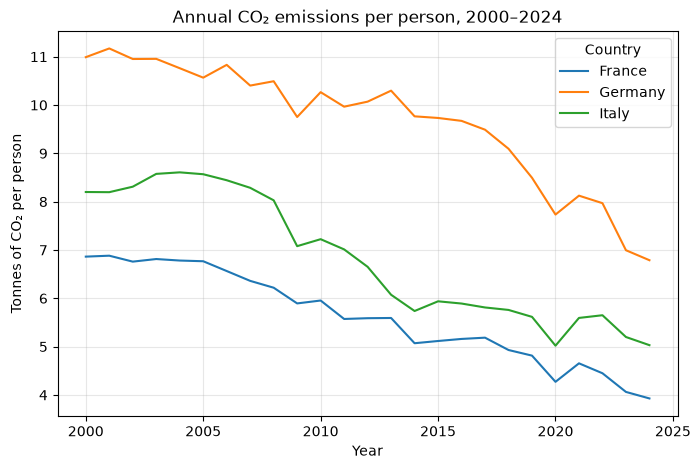

In [18]:
plot_co2(
    co2_focus,
    "co2_per_capita",
    "Annual CO₂ emissions per person, 2000–2024",
    "Tonnes of CO₂ per person",
)

<Axes: title={'center': 'France: GDP and CO₂ (2000 = 100)'}, xlabel='Year', ylabel='Index (2000 = 100)'>

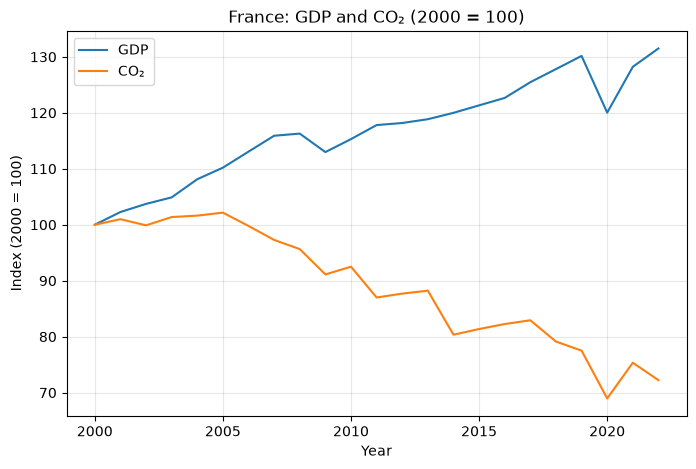

In [19]:
from powering_the_planet.plots import plot_gdp_co2_indexed

plot_gdp_co2_indexed(gdp_co2, "France")

<Axes: title={'center': 'Germany: GDP and CO₂ (2000 = 100)'}, xlabel='Year', ylabel='Index (2000 = 100)'>

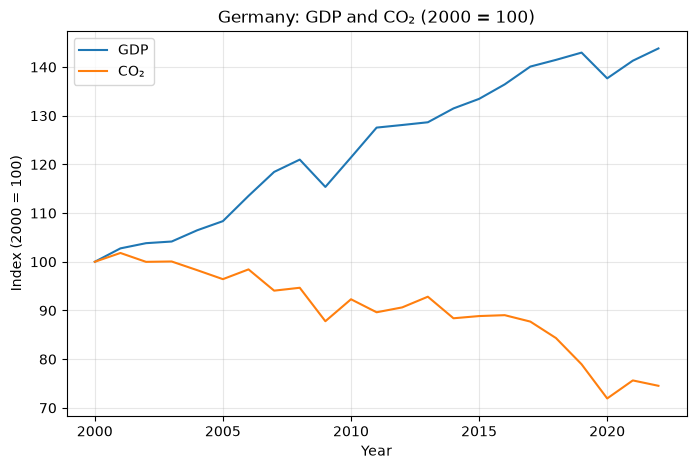

In [20]:
plot_gdp_co2_indexed(gdp_co2, "Germany")

<Axes: title={'center': 'Italy: GDP and CO₂ (2000 = 100)'}, xlabel='Year', ylabel='Index (2000 = 100)'>

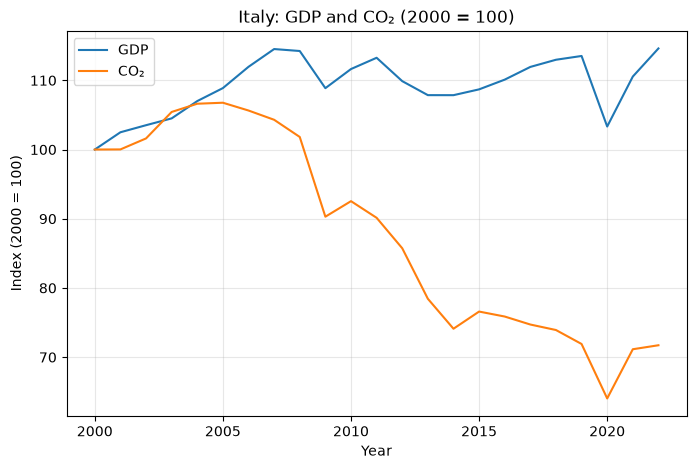

In [21]:
plot_gdp_co2_indexed(gdp_co2, "Italy")

## 5. Conclusion

France, Germany, and Italy reached lower fossil-fuel shares in 2025 than in 2000, but their source-by-source paths differed. France's coal, oil, and gas shares all fell. Germany's renewable share rose strongly, yet its total fossil-fuel share changed little as coal fell while oil and gas rose and nuclear energy fell to zero. In Italy, coal and oil lost share while gas and renewables gained.

Annual CO₂ emissions and emissions per person were lower in 2024 than in 2000 in all three countries. GDP was higher and annual CO₂ emissions lower in 2022 than in 2000; CO₂ per unit of GDP also fell. The year-by-year comparison found 26 country-year cases where GDP rose while CO₂ fell relative to the preceding year.

These are descriptive comparisons. The energy, emissions, and GDP series end in different years, and the analysis does not isolate the causes of the emissions changes.

## 6. Data sources and scope

The energy figures come from [Our World in Data's energy dataset, version 2026-09-10](https://catalog.ourworldindata.org/garden/energy/2026-09-10/owid_energy/owid_energy.csv). The coal, oil, gas, nuclear-energy, and renewable-energy shares are percentages of total energy supply. The fossil-fuel share summarizes coal, oil, and gas.

The CO₂ and GDP figures come from [Our World in Data's CO₂ dataset, version 2026-11-10](https://catalog.ourworldindata.org/garden/emissions/2026-11-10/owid_co2/owid_co2.csv). Annual CO₂ emissions cover fossil fuels and industry; land-use change is excluded. “Total” means the countrywide amount, while “per person” divides it by population.

The CSV files are stored in `data/` and excluded from Git. If a file is missing, `data.py` downloads the dated version automatically. An existing local copy is reused.